# Paso 1: Filtro Inicial de Acciones

### Fase 1.1: Descarga y Filtrado de Acciones por Volumen Promedio

In [130]:
import pandas as pd
import yfinance as yf
import warnings
import requests

# Ignorar warnings para una salida más limpia
warnings.filterwarnings('ignore', category=FutureWarning)

print("Obteniendo la lista de tickers del S&P 500 desde Wikipedia...")
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
# Usar requests con un User-Agent personalizado para evitar el error 403
header = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}
response = requests.get(url, headers=header)
tabla_sp500 = pd.read_html(response.text)[0]
# Reemplazar puntos por guiones para la compatibilidad con yfinance (ej. BRK.B -> BRK-B)
tickers_muestra = tabla_sp500['Symbol'].str.replace('.', '-', regex=False).tolist()

# Diccionario para almacenar las acciones que pasen el filtro
acciones_validas = {}

print(f"Descargando datos para {len(tickers_muestra)} acciones usando yfinance (descarga en bloque para mayor velocidad)...")

# Descargar los últimos 5 años de datos en bloque para optimizar el rendimiento, incluyendo SPY
datos_bloque = yf.download(tickers_muestra + ['SPY'], period="5y", progress=False, auto_adjust=False)

# Filtrar acciones que tengan un volumen promedio mayor a 1,000,000
for ticker in tickers_muestra + ['SPY']:
    try:
        # Al descargar múltiples tickers, yfinance devuelve un MultiIndex en las columnas
        if isinstance(datos_bloque.columns, pd.MultiIndex):
            # Extraemos la información correspondiente solo a este ticker
            datos_temp = datos_bloque.xs(ticker, axis=1, level=1, drop_level=True).copy()
        else:
            datos_temp = datos_bloque.copy()

        # Limpiar valores nulos específicos de este ticker
        datos_temp = datos_temp.dropna(subset=['Close'])

        if not datos_temp.empty and 'Volume' in datos_temp.columns:
            # Asegurar que la fecha sea una columna normal
            datos_temp = datos_temp.reset_index()

            # Renombrar columna de fecha si es necesario
            if 'index' in datos_temp.columns and 'Date' not in datos_temp.columns:
                datos_temp = datos_temp.rename(columns={'index': 'Date'})

            volumen_promedio = datos_temp['Volume'].mean()
            if volumen_promedio > 1000000 or ticker == 'SPY':
                # Convertimos el ticker a minúsculas para mantener la compatibilidad con el resto del código
                acciones_validas[ticker.lower()] = datos_temp
    except Exception as error:
        print(f"Error procesando {ticker}: {error}")

print(f"Se encontraron {len(acciones_validas)} acciones válidas de {len(tickers_muestra)} analizadas.")
print("Primeras 30 acciones válidas encontradas:", list(acciones_validas.keys())[:30])


Obteniendo la lista de tickers del S&P 500 desde Wikipedia...
Descargando datos para 503 acciones usando yfinance (descarga en bloque para mayor velocidad)...
Se encontraron 422 acciones válidas de 503 analizadas.
Primeras 30 acciones válidas encontradas: ['mmm', 'aos', 'abt', 'abbv', 'acn', 'adbe', 'amd', 'aes', 'afl', 'a', 'apd', 'abnb', 'akam', 'alb', 'are', 'lnt', 'all', 'googl', 'goog', 'mo', 'amzn', 'amcr', 'aee', 'aep', 'axp', 'aig', 'amt', 'awk', 'ame', 'amgn']


### Fase 1.2: Consolidación de Precios de Cierre y Retornos Diarios

In [131]:
import numpy as np
import yfinance as yf
import pandas as pd

# Consolidar los precios de cierre ajustados de las acciones válidas
lista_precios = []
for ticker, df_accion in acciones_validas.items():
    df_temp = df_accion[['Date', 'Close']].copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.rename(columns={'Close': ticker})
    lista_precios.append(df_temp.set_index('Date'))

# Unir todos los dataframes en uno solo
df_precios_unidos = pd.concat(lista_precios, axis=1, join='inner')

# Descargar datos reales de SPY para usar como Market
print("Descargando datos de SPY como referencia de mercado...")
spy_data = yf.download('SPY', period='5y', progress=False, auto_adjust=False)
if isinstance(spy_data.columns, pd.MultiIndex):
    spy_close = spy_data['Close']['SPY'].copy()
else:
    spy_close = spy_data['Close'].copy()

spy_close.index = pd.to_datetime(spy_close.index)
spy_close = spy_close.rename('Market')

# Unir la columna Market al dataframe consolidado de precios alineando las fechas
df_precios_unidos = df_precios_unidos.join(spy_close, how='inner')

# Calcular retornos diarios
retornos_diarios = df_precios_unidos.pct_change().dropna()
print("Primeras filas de los retornos diarios (incluyendo SPY como 'Market'):")
display(retornos_diarios.head())

Descargando datos de SPY como referencia de mercado...
Primeras filas de los retornos diarios (incluyendo SPY como 'Market'):


,mmm,aos,abt,abbv,acn,adbe,amd,aes,afl,a,...,wmb,wday,wynn,xel,xyl,yum,zbh,zts,spy,Market
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-02,-0.006932,0.001412,0.008377,0.011118,-0.063118,-0.014879,0.029526,-0.000670,0.003238,0.006600,...,0.019070,-0.003266,-0.018370,0.012048,0.009021,-0.004170,0.002612,0.008538,0.007395,0.007395
2026-10-05,0.008030,0.003877,0.026667,0.011186,-0.019356,0.004628,-0.003407,-0.000671,0.007531,0.020920,...,0.003828,0.015150,0.017001,0.001260,0.006189,0.006245,0.037150,0.024681,0.006743,0.006743
2026-10-06,0.002758,-0.001229,-0.019381,0.003499,-0.008459,-0.002806,0.027970,0.002013,0.011123,-0.011443,...,0.022313,-0.012754,-0.007127,0.017345,0.020992,0.020953,-0.020640,-0.001120,0.005498,0.005498
2026-10-07,-0.009289,-0.027417,0.005807,0.017511,0.016753,-0.022468,-0.005482,0.000000,-0.007832,-0.001417,...,-0.012847,-0.012276,-0.021535,-0.004262,-0.026298,0.003647,-0.013269,0.003084,-0.002400,-0.002400
2026-10-08,0.009006,0.022046,-0.002431,0.003906,0.059601,0.035572,-0.038987,0.000000,0.019514,-0.005441,...,0.012315,0.019266,0.004268,0.012980,0.001670,0.018881,0.004407,0.021384,-0.004233,-0.004233


# Paso 2: Análisis Fundamental y Modelos Financieros

### Fase 2.1: Cálculo del CAPM y Beta de Hamada

In [132]:
import yfinance as yf
import pandas as pd
import numpy as np

# Definir variables financieras de tasa libre de riesgo y retorno de mercado
tasa_libre_riesgo_anual = 0.04
retorno_mercado_anual = retornos_diarios['Market'].mean() * 252
varianza_mercado = retornos_diarios['Market'].var() * 252

metricas_acciones = []
tasa_impuestos = 0.21

print("Calculando métricas y consultando Debt-to-Equity en Yahoo Finance (puede tardar un momento)...")

for ticker in acciones_validas.keys():
    if ticker not in retornos_diarios.columns or ticker == 'Market':
        continue

    # Calcular Beta Histórica
    covarianza_activo_mercado = retornos_diarios[ticker].cov(retornos_diarios['Market']) * 252
    beta_apalancada = covarianza_activo_mercado / (retornos_diarios['Market'].var() * 252)

    # Retorno Esperado usando CAPM tradicional
    retorno_esperado_capm = tasa_libre_riesgo_anual + beta_apalancada * (retorno_mercado_anual - tasa_libre_riesgo_anual)

    # Consultar el ratio real de Deuda/Capital (D/E) desde Yahoo Finance
    try:
        de_ratio = yf.Ticker(ticker).info.get('debtToEquity')
        if de_ratio is not None:
            # yfinance entrega el ratio en porcentaje, lo pasamos a decimal
            relacion_deuda_capital = de_ratio / 100.0
        else:
            # Valor por defecto (fallback) si no hay datos
            relacion_deuda_capital = 0.50
    except Exception:
        # Valor de respaldo en caso de error de conexión o parseo
        relacion_deuda_capital = 0.50

    # Beta Desapalancada de Hamada (Beta_U)
    beta_desapalancada = beta_apalancada / (1 + (1 - tasa_impuestos) * relacion_deuda_capital)

    # Retorno Esperado ajustado por Beta de Hamada
    retorno_esperado_hamada = tasa_libre_riesgo_anual + beta_desapalancada * (retorno_mercado_anual - tasa_libre_riesgo_anual)

    metricas_acciones.append({
        'Activo': ticker,
        'Beta_Apalancada': beta_apalancada,
        'Retorno_Esperado_CAPM': retorno_esperado_capm,
        'Relacion_D_E': relacion_deuda_capital,
        'Beta_Hamada_Desapalancada': beta_desapalancada,
        'Retorno_Esperado_Hamada': retorno_esperado_hamada
    })

# Convertir las métricas a DataFrame
df_metricas_fundamentales = pd.DataFrame(metricas_acciones)
print("--- Análisis de CAPM y Beta de Hamada ---")
display(df_metricas_fundamentales)

Calculando métricas y consultando Debt-to-Equity en Yahoo Finance (puede tardar un momento)...
--- Análisis de CAPM y Beta de Hamada ---


,Activo,Beta_Apalancada,Retorno_Esperado_CAPM,Relacion_D_E,Beta_Hamada_Desapalancada,Retorno_Esperado_Hamada
0,mmm,0.857009,-0.255094,3.03502,0.252235,-0.046852
1,aos,0.236934,-0.041583,0.39219,0.180889,-0.022285
2,abt,0.270156,-0.053023,0.60899,0.182402,-0.022806
3,abbv,0.316188,-0.068873,0.50000,0.226658,-0.038045
4,acn,-0.550066,0.229404,0.40283,-0.417274,0.183680
...,...,...,...,...,...,...
417,xyl,-0.115626,0.079814,0.28789,-0.094202,0.072436
418,yum,0.203265,-0.029990,0.50000,0.145710,-0.010172
419,zbh,1.032647,-0.315571,0.60172,0.699929,-0.201006
420,zts,1.061452,-0.325489,2.80260,0.330253,-0.073716


# Paso 3: Análisis Técnico con Indicadores

### Fase 3.1: Medias Móviles, RSI, MACD y Oscilador Estocástico

Acciones que muestran perfil 'Saliendo de Sobreventa':
['aptv', 'cat', 'csco', 'cmi', 'dell', 'ftnt', 'fcx', 'hpq', 'ilmn', 'lite', 'mrvl', 'mchp', 'panw', 'rddt', 'stx', 'smci', 'ter']

Mostrando el gráfico de la primera acción encontrada: APTV


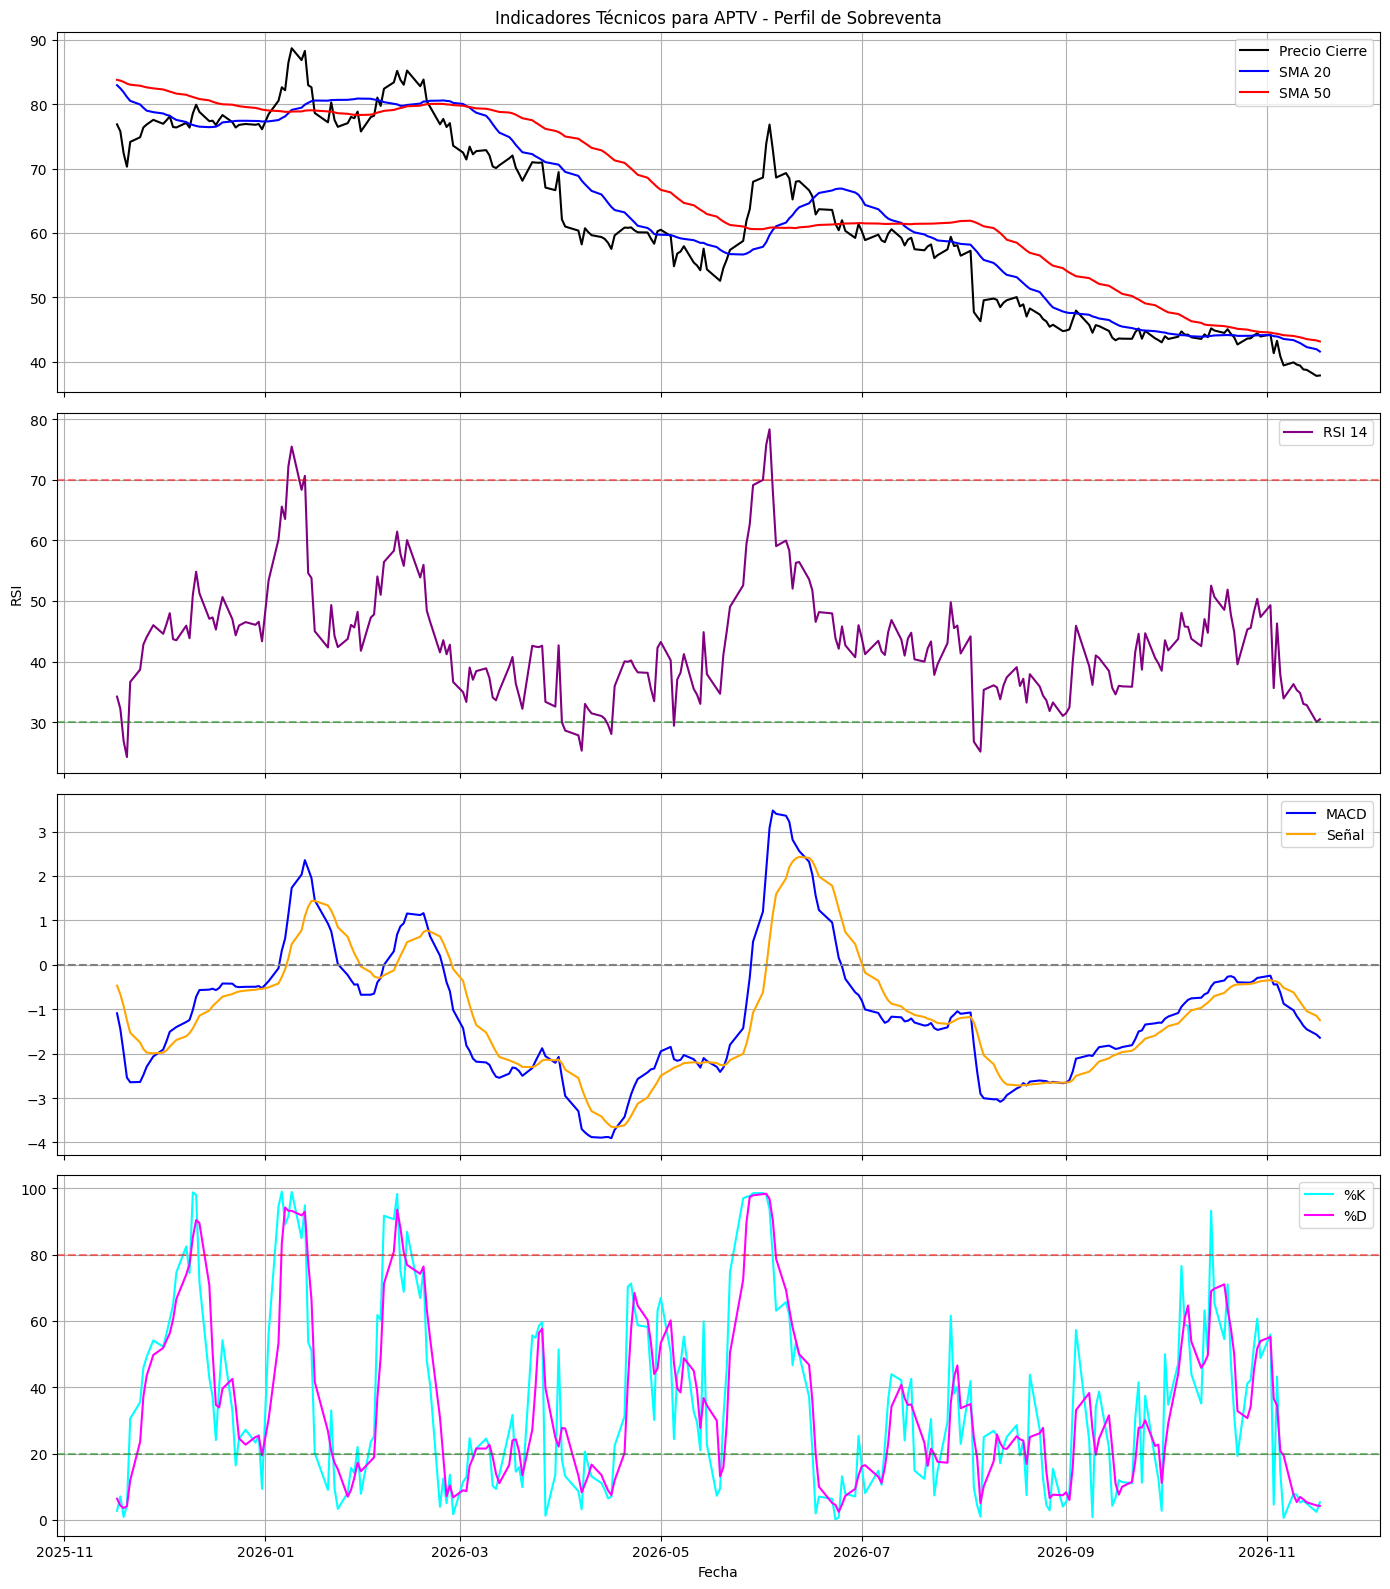

In [133]:
import matplotlib.pyplot as plt
import pandas as pd

# Escáner: Buscar acciones saliendo de sobreventa
acciones_sobreventa = []
indicadores_sobreventa = {}

for ticker, df_accion in acciones_validas.items():
    df_tecnico = df_accion.copy()
    df_tecnico['Date'] = pd.to_datetime(df_tecnico['Date'])
    df_tecnico = df_tecnico.sort_values('Date').set_index('Date')

    # RSI 14
    diferencia_precios = df_tecnico['Close'].diff()
    ganancia = (diferencia_precios.where(diferencia_precios > 0, 0)).ewm(alpha=1/14, adjust=False).mean()
    perdida = (-diferencia_precios.where(diferencia_precios < 0, 0)).ewm(alpha=1/14, adjust=False).mean()
    relacion_fuerza = ganancia / perdida
    df_tecnico['RSI_14'] = 100 - (100 / (1 + relacion_fuerza))

    # Oscilador Estocástico
    minimo_14 = df_tecnico['Low'].rolling(window=14).min()
    maximo_14 = df_tecnico['High'].rolling(window=14).max()
    df_tecnico['Estocastico_K'] = 100 * ((df_tecnico['Close'] - minimo_14) / (maximo_14 - minimo_14))
    df_tecnico['Estocastico_D'] = df_tecnico['Estocastico_K'].rolling(window=3).mean()

    # MACD
    ema_12 = df_tecnico['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tecnico['Close'].ewm(span=26, adjust=False).mean()
    df_tecnico['MACD'] = ema_12 - ema_26
    df_tecnico['MACD_Senal'] = df_tecnico['MACD'].ewm(span=9, adjust=False).mean()

    # Medias Móviles Simples (SMA 20 y 50)
    df_tecnico['SMA_20'] = df_tecnico['Close'].rolling(window=20).mean()
    df_tecnico['SMA_50'] = df_tecnico['Close'].rolling(window=50).mean()

    indicadores_sobreventa[ticker] = df_tecnico

    # Condiciones de salida de sobreventa (últimos 2 días)
    if len(df_tecnico) > 2:
        ultimo_rsi = df_tecnico['RSI_14'].iloc[-1]
        penultimo_rsi = df_tecnico['RSI_14'].iloc[-2]

        ultima_K = df_tecnico['Estocastico_K'].iloc[-1]
        ultima_D = df_tecnico['Estocastico_D'].iloc[-1]
        penultima_K = df_tecnico['Estocastico_K'].iloc[-2]
        penultima_D = df_tecnico['Estocastico_D'].iloc[-2]

        # 1. RSI estaba cerca o debajo de 30 y ahora está subiendo (pero aún por debajo de 45)
        criterio_rsi = (ultimo_rsi > penultimo_rsi) and (ultimo_rsi < 45) and (penultimo_rsi < 35)

        # 2. Estocástico cruzando al alza en zona de sobreventa (< 30)
        criterio_estocastico = (ultima_K > ultima_D) and (penultima_K <= penultima_D) and (ultima_K < 30)

        if criterio_rsi or criterio_estocastico:
            acciones_sobreventa.append(ticker)

print("Acciones que muestran perfil 'Saliendo de Sobreventa':")
print(acciones_sobreventa)

if acciones_sobreventa:
    activo_tecnico = acciones_sobreventa[0]
    print(f"\nMostrando el gráfico de la primera acción encontrada: {activo_tecnico.upper()}")
else:
    activo_tecnico = list(acciones_validas.keys())[0]
    print(f"\nNo se encontraron acciones con ese perfil exacto hoy. Mostrando: {activo_tecnico.upper()}")

df_tecnico = indicadores_sobreventa[activo_tecnico]

# Visualización gráfica de los indicadores
df_grafico = df_tecnico.tail(252) # Último año bursátil
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

# Gráfico 1: Precios y Medias Móviles
ax1.plot(df_grafico.index, df_grafico['Close'], label='Precio Cierre', color='black')
ax1.plot(df_grafico.index, df_grafico['SMA_20'], label='SMA 20', color='blue')
ax1.plot(df_grafico.index, df_grafico['SMA_50'], label='SMA 50', color='red')
ax1.set_title(f'Indicadores Técnicos para {activo_tecnico.upper()} - Perfil de Sobreventa')
ax1.legend()
ax1.grid(True)

# Gráfico 2: RSI
ax2.plot(df_grafico.index, df_grafico['RSI_14'], color='purple', label='RSI 14')
ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
ax2.set_ylabel('RSI')
ax2.legend()
ax2.grid(True)

# Gráfico 3: MACD
ax3.plot(df_grafico.index, df_grafico['MACD'], color='blue', label='MACD')
ax3.plot(df_grafico.index, df_grafico['MACD_Senal'], color='orange', label='Señal')
ax3.axhline(0, color='gray', linestyle='--')
ax3.legend()
ax3.grid(True)

# Gráfico 4: Estocástico
ax4.plot(df_grafico.index, df_grafico['Estocastico_K'], color='cyan', label='%K')
ax4.plot(df_grafico.index, df_grafico['Estocastico_D'], color='magenta', label='%D')
ax4.axhline(80, color='red', linestyle='--', alpha=0.5)
ax4.axhline(20, color='green', linestyle='--', alpha=0.5)
ax4.legend()
ax4.grid(True)

plt.xlabel('Fecha')
plt.tight_layout()
plt.show()


### Fase 3.2: Categorización de Activos por Volatilidad y Direccionalidad
En esta fase clasificamos dinámicamente las acciones del universo analizado de acuerdo con dos dimensiones clave:
1. **Volatilidad Anualizada**: Clasificadas en *Alta Volatilidad* o *Baja Volatilidad* utilizando el valor medio de volatilidad como umbral.
2. **Direccionalidad (RSI)**: Clasificadas en tendencia *Alcista* (RSI de 14 días > 50) o *Bajista* (RSI de 14 días <= 50).

In [134]:
# 1. Calcular volatilidad histórica anualizada para todos los activos
volatilidades = retornos_activos.std() * np.sqrt(252)
umbral_volatilidad = volatilidades.median()

# 2. Calcular el último RSI_14 para cada activo
rsis_actuales = {}
for ticker, df_accion in acciones_validas.items():
    if ticker not in retornos_activos.columns:
        continue
    precios_close = df_accion.sort_values('Date')['Close']
    delta = precios_close.diff()
    ganancia = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    perdida = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = ganancia / perdida
    rsi_serie = 100 - (100 / (1 + rs))
    rsis_actuales[ticker] = rsi_serie.iloc[-1]

# 3. Clasificar según condiciones cuantitativas
categorias_acciones = []
for ticker in volatilidades.index:
    vol = volatilidades[ticker]
    rsi = rsis_actuales.get(ticker, 50.0)

    # Determinar categoría de volatilidad
    cat_vol = "Alta Volatilidad" if vol > umbral_volatilidad else "Baja Volatilidad"

    # Determinar dirección de la tendencia
    cat_dir = "Alcista" if rsi > 50 else "Bajista"

    categorias_acciones.append({
        'Activo': ticker,
        'Volatilidad_Anualizada': vol,
        'RSI_Actual': rsi,
        'Categoria_Volatilidad': cat_vol,
        'Direccionalidad': cat_dir,
        'Cuadrante': f"{cat_vol} - {cat_dir}"
    })

df_categorizacion = pd.DataFrame(categorias_acciones)
print("--- Clasificación Cuantitativa de Activos ---")
display(df_categorizacion.sort_values(by='Cuadrante'))

--- Clasificación Cuantitativa de Activos ---


,Activo,Volatilidad_Anualizada,RSI_Actual,Categoria_Volatilidad,Direccionalidad,Cuadrante
0,mmm,0.374220,57.872178,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
188,gpn,0.621661,51.734271,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
185,gm,0.420236,52.643986,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
184,gis,0.391068,58.174531,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
181,gen,0.535427,72.695360,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
...,...,...,...,...,...,...
307,pm,0.289319,39.339193,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
354,stt,0.249719,40.458024,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
156,exe,0.255723,30.444689,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
147,etr,0.179667,48.913814,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista


In [135]:
with open('/content/copia_de_cuantitative_auto_stocks.py', 'r') as f:
    contenido_completo = f.read()

# Buscaremos segmentos relacionados con categorización, volatilidad, tendencias o direccionalidad en el Paso 3
lineas_codigo = contenido_completo.split('\n')
for i, linea in enumerate(lineas_codigo):
    if 'volatilidad' in linea.lower() or 'trend' in linea.lower() or 'categoria' in linea.lower() or 'direcciona' in linea.lower() or 'estocastico' in linea.lower():
        if 150 < i < 350:
            print(f'Línea {i}: {linea}')

Línea 245: Calcular indicadores econométricos para las acciones seleccionadas: media, varianza, volatilidad, relación riesgo vs rendimiento, covarianza, correlación y cointegración.


# Paso 4: Análisis Econométrico y Riesgo/Rendimiento

### Fase 4.1: Retornos, Volatilidad, Matriz de Correlación y Cointegración

--- Métricas Econométricas de Activos Individuales ---


,Retorno_Medio_Anual,Varianza_Anual,Volatilidad_Anual,Ratio_Sharpe
mmm,0.860761,0.140041,0.374220,2.193257
aos,0.909363,0.103953,0.322417,2.696389
abt,0.652497,0.089991,0.299984,2.041764
abbv,0.933892,0.046363,0.215320,4.151460
acn,1.031234,0.240743,0.490655,2.020224
...,...,...,...,...
xyl,-0.348747,0.268106,0.517789,-0.750783
yum,1.301739,0.066781,0.258421,4.882499
zbh,1.235783,0.226482,0.475902,2.512668
zts,1.532636,0.174133,0.417292,3.576958


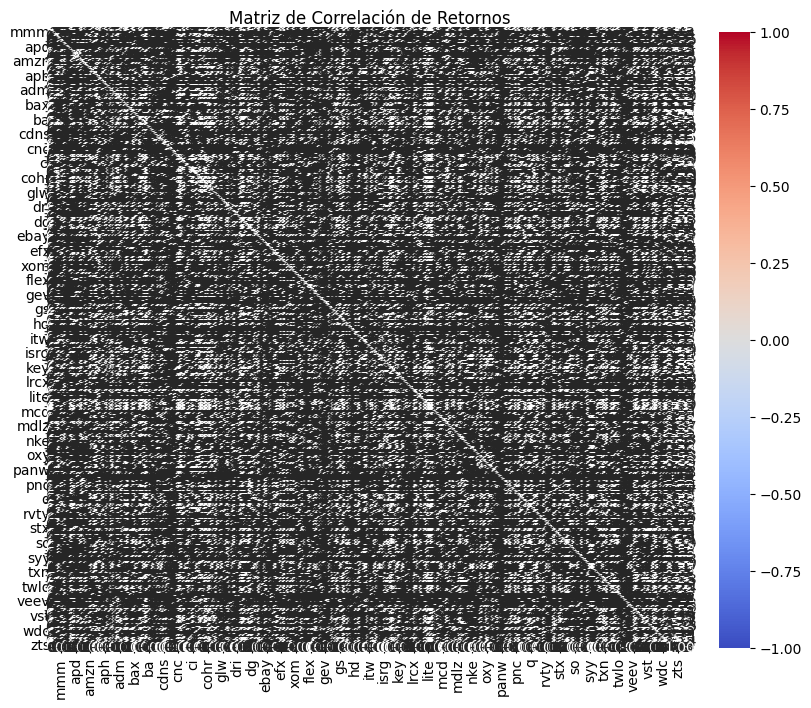


--- Test de Cointegración: mmm vs aos ---
p-valor: 0.1276
No hay evidencia sólida de cointegración.


In [136]:
import seaborn as sns
from statsmodels.tsa.stattools import coint

# Excluimos la columna del mercado simulado
retornos_activos = retornos_diarios.drop(columns=['Market'], errors='ignore')

# Métricas de riesgo y rendimiento
retorno_medio_anual = retornos_activos.mean() * 252
varianza_anual = retornos_activos.var() * 252
volatilidad_anual = retornos_activos.std() * np.sqrt(252)

# Ratio de Sharpe
ratio_sharpe = (retorno_medio_anual - tasa_libre_riesgo_anual) / volatilidad_anual

# Resumen de métricas econométricas
df_econometrico = pd.DataFrame({
    'Retorno_Medio_Anual': retorno_medio_anual,
    'Varianza_Anual': varianza_anual,
    'Volatilidad_Anual': volatilidad_anual,
    'Ratio_Sharpe': ratio_sharpe
})

print("--- Métricas Econométricas de Activos Individuales ---")
display(df_econometrico)

# Matriz de covarianza y correlación
matriz_cov = retornos_activos.cov() * 252
matriz_corr = retornos_activos.corr()

# Visualizar mapa de calor de correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Retornos')
plt.show()

# Test de Cointegración para el primer par de activos
simbolos = list(retornos_activos.columns)
if len(simbolos) >= 2:
    activo1, activo2 = simbolos[0], simbolos[1]
    puntos_precio1 = df_precios_unidos[activo1]
    puntos_precio2 = df_precios_unidos[activo2]
    p_valor = coint(puntos_precio1, puntos_precio2)[1]

    print(f"\n--- Test de Cointegración: {activo1} vs {activo2} ---")
    print(f"p-valor: {p_valor:.4f}")
    if p_valor < 0.05:
        print("Existe evidencia de que los activos están cointegrados.")
    else:
        print("No hay evidencia sólida de cointegración.")

# Paso 5: Construcción y Análisis de Portafolios

### Fase 5.1: Portafolio Equiponderado

In [137]:
# Crear pesos iguales para todos los activos
num_activos = len(retornos_activos.columns)
pesos_iguales = np.array([1 / num_activos] * num_activos)

# Calcular rendimiento del portafolio equiponderado
rendimiento_portafolio = np.dot(pesos_iguales, retorno_medio_anual)

# Calcular varianza y volatilidad del portafolio
varianza_portafolio = np.dot(pesos_iguales.T, np.dot(matriz_cov, pesos_iguales))
volatilidad_portafolio = np.sqrt(varianza_portafolio)

# Sharpe Ratio
ratio_sharpe_portafolio = (rendimiento_portafolio - tasa_libre_riesgo_anual) / volatilidad_portafolio

print("--- Métricas del Portafolio Equiponderado ---")
print(f"Retorno Esperado Anualizado: {rendimiento_portafolio:.4f}")
print(f"Volatilidad Anualizada: {volatilidad_portafolio:.4f}")
print(f"Ratio de Sharpe: {ratio_sharpe_portafolio:.4f}")

--- Métricas del Portafolio Equiponderado ---
Retorno Esperado Anualizado: 0.1871
Volatilidad Anualizada: 0.1637
Ratio de Sharpe: 0.8989


# Paso 6: Optimización de Portafolio con SciPy

### Fase 6.1: Frontera Eficiente, GMV y Máximo Sharpe

,Portafolio,Retorno_Esperado,Volatilidad,Ratio_Sharpe
0,Equiponderado,0.187128,0.163679,0.898879
1,GMV,0.214278,0.015198,11.466812
2,Max Sharpe,0.893871,0.035226,24.239607


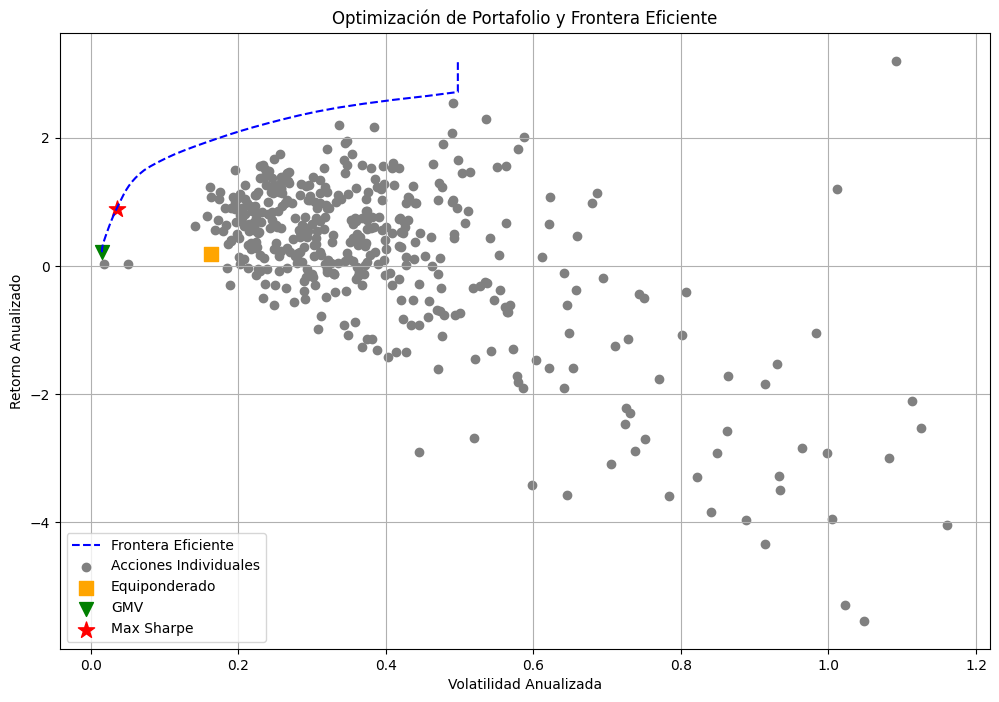

In [138]:
import scipy.optimize as sco

# Función para calcular estadísticas del portafolio dado unos pesos
def calcular_estadisticas_portafolio(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_anual)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

# Funciones a minimizar para las optimizaciones
def minimizar_sharpe(pesos):
    return -calcular_estadisticas_portafolio(pesos)[2]

def minimizar_volatilidad(pesos):
    return calcular_estadisticas_portafolio(pesos)[1]

# Restricciones de pesos (suma de pesos = 1, y límites individuales del 35%)
restricciones = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites = tuple((0, 0.35) for _ in range(num_activos))
pesos_iniciales = num_activos * [1. / num_activos,]

# 1. Optimización Máximo Sharpe
opt_max_sharpe = sco.minimize(minimizar_sharpe, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
pesos_max_sharpe = opt_max_sharpe.x
stats_max_sharpe = calcular_estadisticas_portafolio(pesos_max_sharpe)

# 2. Optimización Mínima Varianza Global (GMV)
opt_gmv = sco.minimize(minimizar_volatilidad, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
pesos_gmv = opt_gmv.x
stats_gmv = calcular_estadisticas_portafolio(pesos_gmv)

# 3. Construcción de la Frontera Eficiente
rendimientos_objetivo = np.linspace(stats_gmv[0], df_econometrico['Retorno_Medio_Anual'].max(), 50)
volatilidades_frontera = []

for r_obj in rendimientos_objetivo:
    rest_ef = (
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x: calcular_estadisticas_portafolio(x)[0] - r_obj}
    )
    opt_ef = sco.minimize(minimizar_volatilidad, pesos_iniciales, method='SLSQP', bounds=limites, constraints=rest_ef)
    volatilidades_frontera.append(opt_ef.fun)

# Mostrar Resultados Comparativos
df_comparativo = pd.DataFrame({
    'Portafolio': ['Equiponderado', 'GMV', 'Max Sharpe'],
    'Retorno_Esperado': [rendimiento_portafolio, stats_gmv[0], stats_max_sharpe[0]],
    'Volatilidad': [volatilidad_portafolio, stats_gmv[1], stats_max_sharpe[1]],
    'Ratio_Sharpe': [ratio_sharpe_portafolio, stats_gmv[2], stats_max_sharpe[2]]
})
display(df_comparativo)

# Graficar la Frontera Eficiente
plt.figure(figsize=(12, 8))
plt.plot(volatilidades_frontera, rendimientos_objetivo, 'b--', label='Frontera Eficiente')
plt.scatter(volatilidad_anual, retorno_medio_anual, color='gray', label='Acciones Individuales')
plt.scatter(volatilidad_portafolio, rendimiento_portafolio, marker='s', color='orange', s=100, label='Equiponderado')
plt.scatter(stats_gmv[1], stats_gmv[0], marker='v', color='green', s=100, label='GMV')
plt.scatter(stats_max_sharpe[1], stats_max_sharpe[0], marker='*', color='red', s=150, label='Max Sharpe')
plt.title('Optimización de Portafolio y Frontera Eficiente')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Anualizado')
plt.legend()
plt.grid(True)
plt.show()

# Paso 7: Simulaciones de Monte Carlo y Recomendaciones Finales

### Fase 7.1: Simulación de Portafolios por Monte Carlo

In [ ]:
num_simulaciones = 5000
resultados_simulados = np.zeros((3, num_simulaciones))

# Correr simulaciones con pesos aleatorios que sumen 1 y no excedan el 35%
for i in range(num_simulaciones):
    pesos_aleatorios = np.random.random(num_activos)
    # Normalizamos pesos de manera simplificada para respetar límites máximos de forma razonable
    pesos_aleatorios = pesos_aleatorios / np.sum(pesos_aleatorios)

    stats_aleatorias = calcular_estadisticas_portafolio(pesos_aleatorios)
    resultados_simulados[0, i] = stats_aleatorias[0]
    resultados_simulados[1, i] = stats_aleatorias[1]
    resultados_simulados[2, i] = stats_aleatorias[2]

# Graficar nube de puntos simulados
plt.figure(figsize=(10, 6))
plt.scatter(resultados_simulados[1], resultados_simulados[0], c=resultados_simulados[2], cmap='viridis', marker='o', s=10, alpha=0.3)
plt.colorbar(label='Ratio de Sharpe')
plt.title('Simulación de Monte Carlo de Portafolios')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Esperado Anualizado')
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Preparar las métricas de cada acción
metricas = []

for ticker in retornos_activos.columns:
    # Rendimiento y Sharpe ya calculados en el entorno
    rendimiento = retorno_medio_anual[ticker]
    sharpe = ratio_sharpe[ticker]
    vol = volatilidad_anual[ticker]

    # Calcular Control Drawdown (calculando Max Drawdown primero)
    precios = df_precios_unidos[ticker]
    maximos_historicos = precios.cummax()
    drawdowns = (precios - maximos_historicos) / maximos_historicos
    max_drawdown = drawdowns.min()  # suele ser un valor negativo
    # Convertimos a Control Drawdown: cuanto menor sea la caída máxima, mayor será este valor
    control_drawdown = 1 + max_drawdown

    # Baja Volatilidad (inversa de la volatilidad, para que a menor vol, mayor puntaje)
    baja_volatilidad = 1 / vol if vol > 0 else 0

    metricas.append({
        'Ticker': ticker,
        'Rendimiento': rendimiento,
        'Sharpe': sharpe,
        'Control_Drawdown': control_drawdown,
        'Baja_Volatilidad': baja_volatilidad
    })

df_metricas = pd.DataFrame(metricas)

# 2. Normalizar métricas (Min-Max) para tenerlas en una escala de 0 a 1
def min_max_norm(serie):
    if serie.max() == serie.min():
        return 1.0
    return (serie - serie.min()) / (serie.max() - serie.min())

df_metricas['Norm_Sharpe'] = min_max_norm(df_metricas['Sharpe'])
df_metricas['Norm_Rendimiento'] = min_max_norm(df_metricas['Rendimiento'])
df_metricas['Norm_Drawdown'] = min_max_norm(df_metricas['Control_Drawdown'])
df_metricas['Norm_Baja_Vol'] = min_max_norm(df_metricas['Baja_Volatilidad'])

# 3. Calcular Score General
# 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad
df_metricas['Score_General'] = (
    0.35 * df_metricas['Norm_Sharpe'] +
    0.25 * df_metricas['Norm_Rendimiento'] +
    0.25 * df_metricas['Norm_Drawdown'] +
    0.15 * df_metricas['Norm_Baja_Vol']
)

# 4. Obtener las top 5 y generar el reporte
top_5 = df_metricas.sort_values(by='Score_General', ascending=False).head(5)

print("=" * 70)
print("                INFORME AUTOMATIZADO: TOP 5 ACCIONES")
print("=" * 70)
print("Fórmula:\nScore General = 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad\n")

reporte = top_5[['Ticker', 'Rendimiento', 'Sharpe', 'Control_Drawdown', 'Baja_Volatilidad', 'Score_General']].copy()
reporte.rename(columns={
    'Rendimiento': 'Retorno Anual',
    'Control_Drawdown': 'Ctrl Drawdown',
    'Baja_Volatilidad': 'Factor Baja Vol'
}, inplace=True)

display(reporte.style.format({
    'Retorno Anual': '{:.2%}',
    'Sharpe': '{:.2f}',
    'Ctrl Drawdown': '{:.2%}',
    'Factor Baja Vol': '{:.2f}',
    'Score_General': '{:.4f}'
}).hide(axis='index'))


EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: ['brk-b', 'cost', 'vlto', 'clx', 'wmt']

--- 1. Análisis CAPM y Beta (Top 5) ---


,Activo,Beta,Retorno_Esperado_CAPM
0,brk-b,0.279601,-0.056275
1,cost,-0.193587,0.106658
2,vlto,-0.282780,0.137370
3,clx,0.465149,-0.120164
4,wmt,-0.015048,0.045181



--- 2. Análisis Técnico Rápido del Líder: BRK-B ---


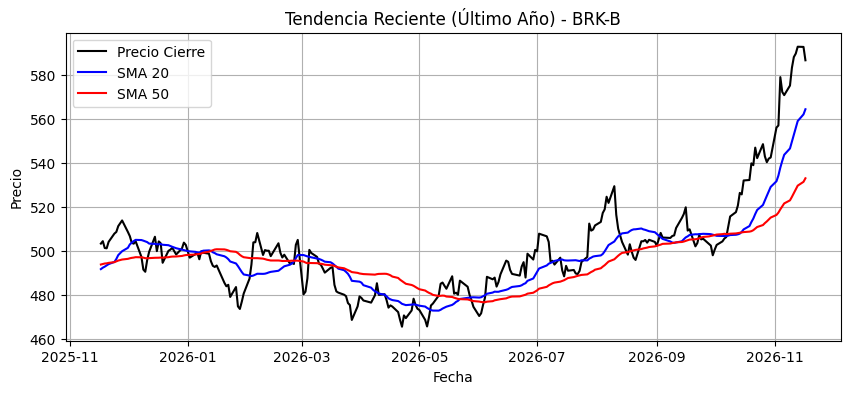


--- 3. Matriz de Correlación Econométrica (Top 5) ---


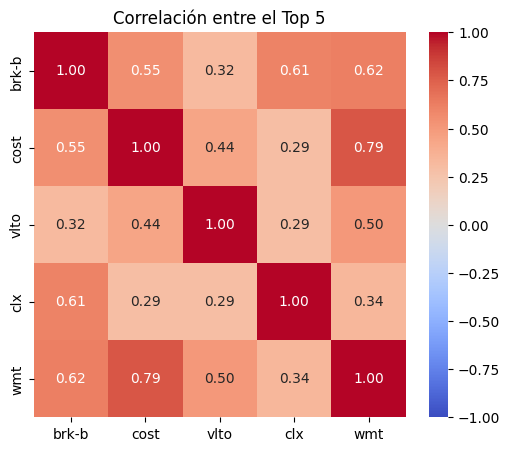


--- 4. Optimización de Portafolio (Top 5) ---
Distribución Óptima (Máximo Sharpe Ratio):
  - BRK-B: 27.04%
  - COST: 34.40%
  - VLTO: 23.49%
  - CLX: 15.07%
  - WMT: 0.00%

Retorno Esperado del Portafolio: 159.07%
Volatilidad del Portafolio: 16.61%
Sharpe Ratio: 9.3378

--- 5. Simulación de Monte Carlo (Top 5) ---


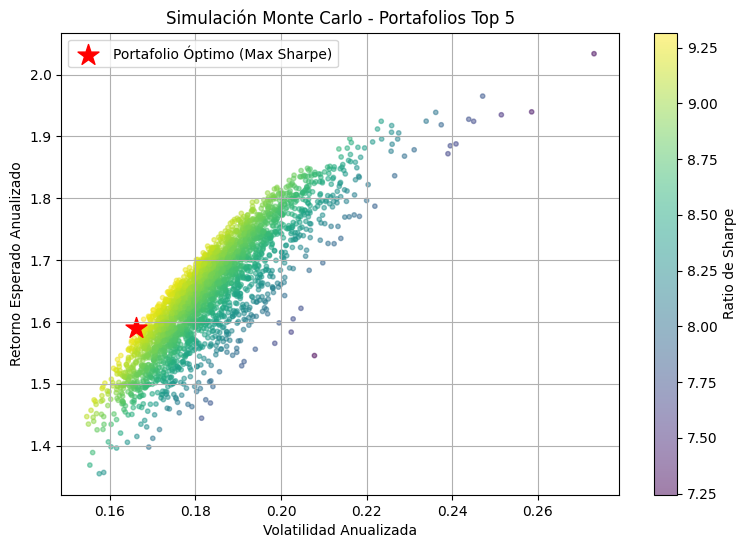

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.optimize as sco
from statsmodels.tsa.stattools import coint

# 0. Extraer los top 5 tickers
top_tickers = top_5['Ticker'].tolist()
print("=" * 70)
print(f"EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: {top_tickers}")
print("=" * 70)

# 1. Filtrar retornos y calcular métricas base
retornos_top5 = retornos_diarios[top_tickers]
retorno_medio_top5 = retornos_top5.mean() * 252
matriz_cov_top5 = retornos_top5.cov() * 252

# 2. CAPM y Beta
print("\n--- 1. Análisis CAPM y Beta (Top 5) ---")
metricas_capm_top5 = []
for ticker in top_tickers:
    cov_mercado = retornos_diarios[ticker].cov(retornos_diarios['Market']) * 252
    beta = cov_mercado / (retornos_diarios['Market'].var() * 252)
    ret_esperado = tasa_libre_riesgo_anual + beta * (retorno_mercado_anual - tasa_libre_riesgo_anual)
    metricas_capm_top5.append({'Activo': ticker, 'Beta': beta, 'Retorno_Esperado_CAPM': ret_esperado})
display(pd.DataFrame(metricas_capm_top5))

# 3. Análisis Técnico del Líder (la acción #1)
lider = top_tickers[0]
print(f"\n--- 2. Análisis Técnico Rápido del Líder: {lider.upper()} ---")
df_lider = acciones_validas[lider].copy()
df_lider['Date'] = pd.to_datetime(df_lider['Date'])
df_lider = df_lider.set_index('Date').sort_index()
df_lider['SMA_20'] = df_lider['Close'].rolling(20).mean()
df_lider['SMA_50'] = df_lider['Close'].rolling(50).mean()

plt.figure(figsize=(10, 4))
plt.plot(df_lider.index[-252:], df_lider['Close'].tail(252), label='Precio Cierre', color='black')
plt.plot(df_lider.index[-252:], df_lider['SMA_20'].tail(252), label='SMA 20', color='blue')
plt.plot(df_lider.index[-252:], df_lider['SMA_50'].tail(252), label='SMA 50', color='red')
plt.title(f'Tendencia Reciente (Último Año) - {lider.upper()}')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

# 4. Matriz de Correlación Top 5
print("\n--- 3. Matriz de Correlación Econométrica (Top 5) ---")
plt.figure(figsize=(6, 5))
sns.heatmap(retornos_top5.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlación entre el Top 5')
plt.show()

# 5. Optimización de Portafolio (Max Sharpe)
print("\n--- 4. Optimización de Portafolio (Top 5) ---")
num_activos_top5 = len(top_tickers)

def calc_stats_top5(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_top5)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov_top5, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

def min_sharpe_top5(pesos):
    return -calc_stats_top5(pesos)[2]

# Restricciones y límites (0 a 100% por ser portafolio concentrado)
restricciones_top5 = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites_top5 = tuple((0, 1.0) for _ in range(num_activos_top5))
pesos_ini_top5 = num_activos_top5 * [1. / num_activos_top5,]

opt_sharpe_top5 = sco.minimize(min_sharpe_top5, pesos_ini_top5, method='SLSQP', bounds=limites_top5, constraints=restricciones_top5)
stats_opt = calc_stats_top5(opt_sharpe_top5.x)

print("Distribución Óptima (Máximo Sharpe Ratio):")
for t, p in zip(top_tickers, opt_sharpe_top5.x):
    print(f"  - {t.upper()}: {p:.2%}")
print(f"\nRetorno Esperado del Portafolio: {stats_opt[0]:.2%}")
print(f"Volatilidad del Portafolio: {stats_opt[1]:.2%}")
print(f"Sharpe Ratio: {stats_opt[2]:.4f}")

# 6. Simulación Monte Carlo
print("\n--- 5. Simulación de Monte Carlo (Top 5) ---")
num_sims = 3000
res_sims = np.zeros((3, num_sims))
for i in range(num_sims):
    w = np.random.random(num_activos_top5)
    w /= np.sum(w)
    s = calc_stats_top5(w)
    res_sims[:, i] = s

plt.figure(figsize=(9, 6))
plt.scatter(res_sims[1], res_sims[0], c=res_sims[2], cmap='viridis', marker='o', s=10, alpha=0.5)
plt.colorbar(label='Ratio de Sharpe')
plt.scatter(stats_opt[1], stats_opt[0], color='red', marker='*', s=250, label='Portafolio Óptimo (Max Sharpe)')
plt.title('Simulación Monte Carlo - Portafolios Top 5')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Esperado Anualizado')
plt.legend()
plt.grid(True)
plt.show()

          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES

Generando gráficos para: BRK-B


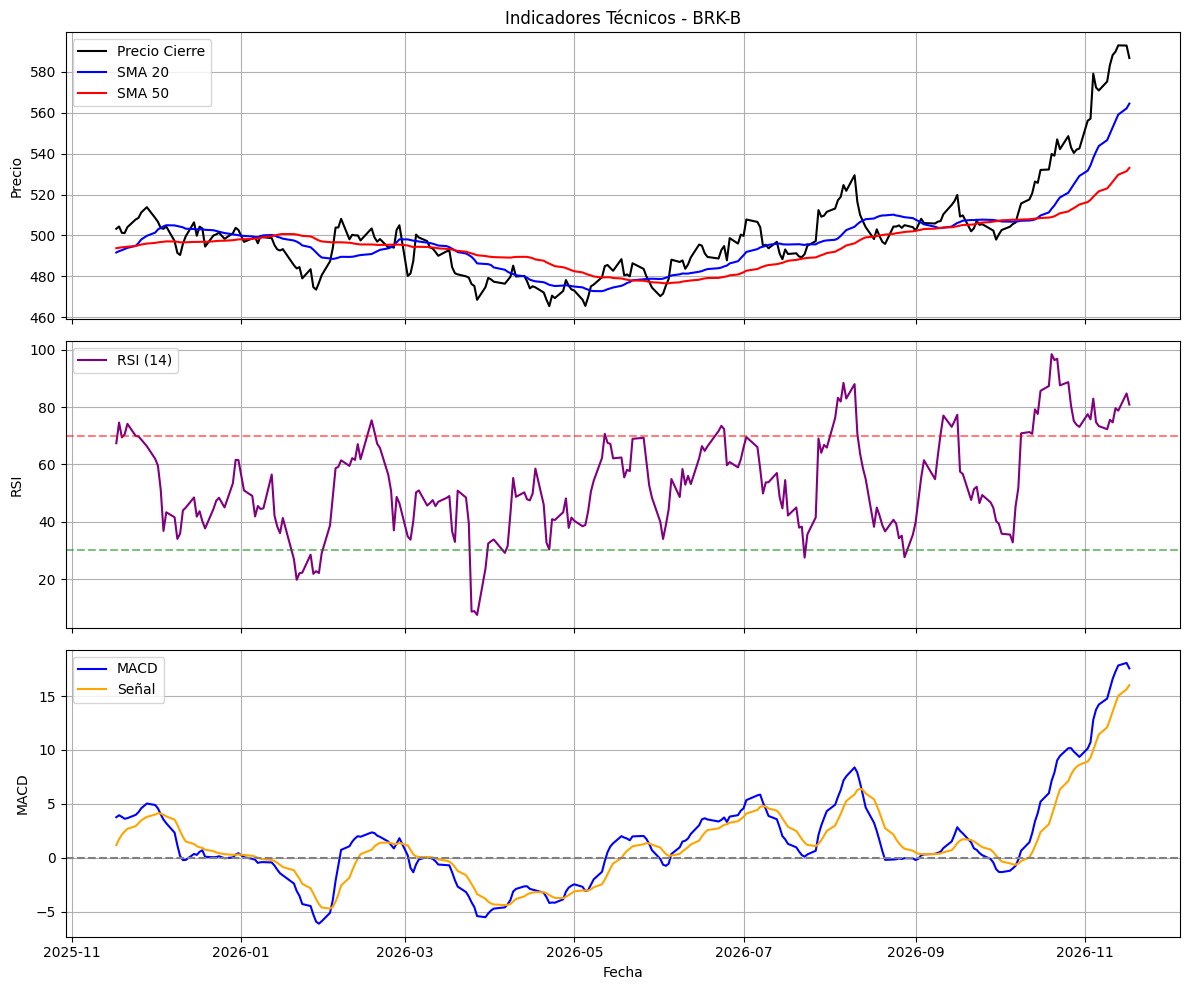


Generando gráficos para: COST


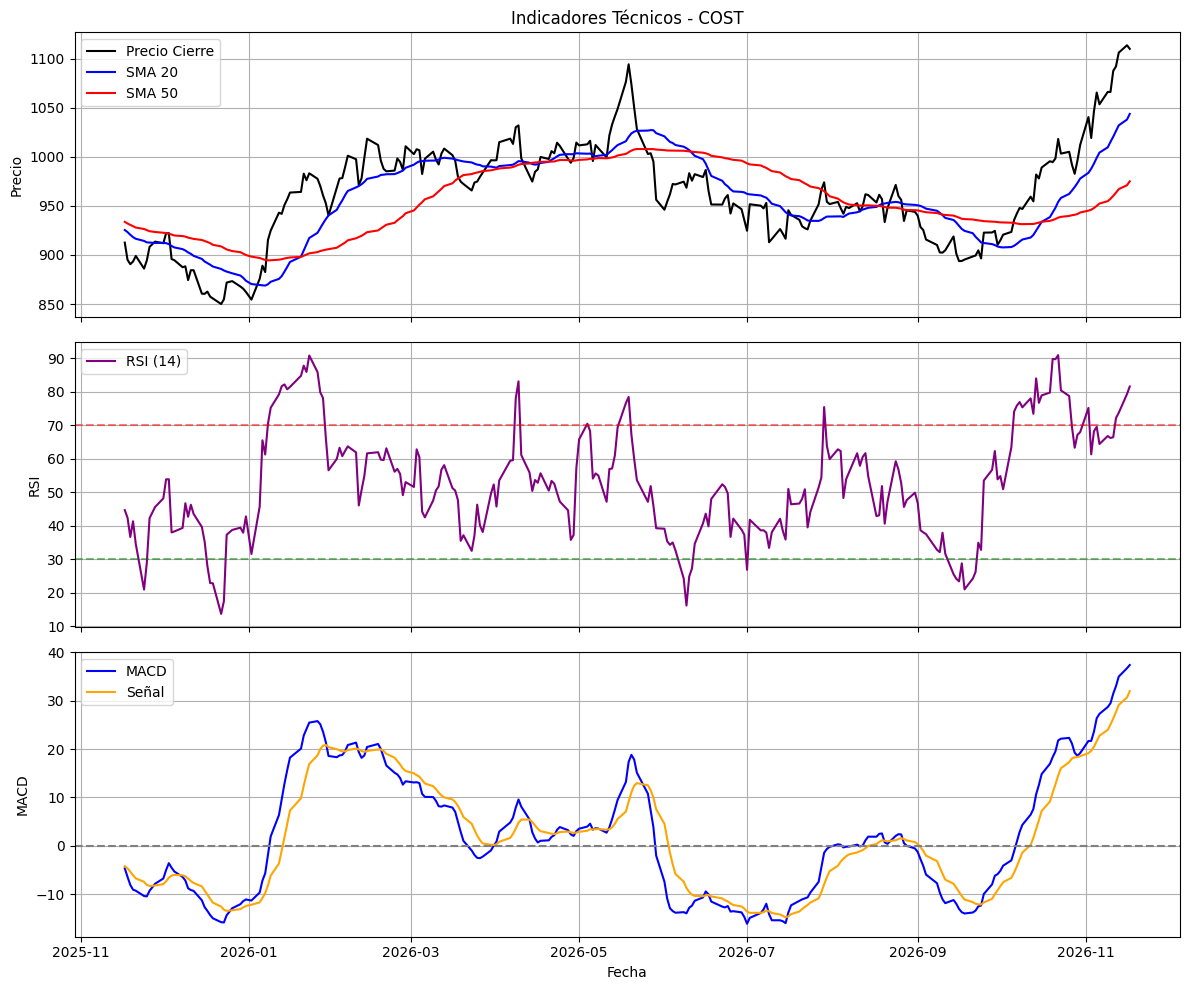


Generando gráficos para: VLTO


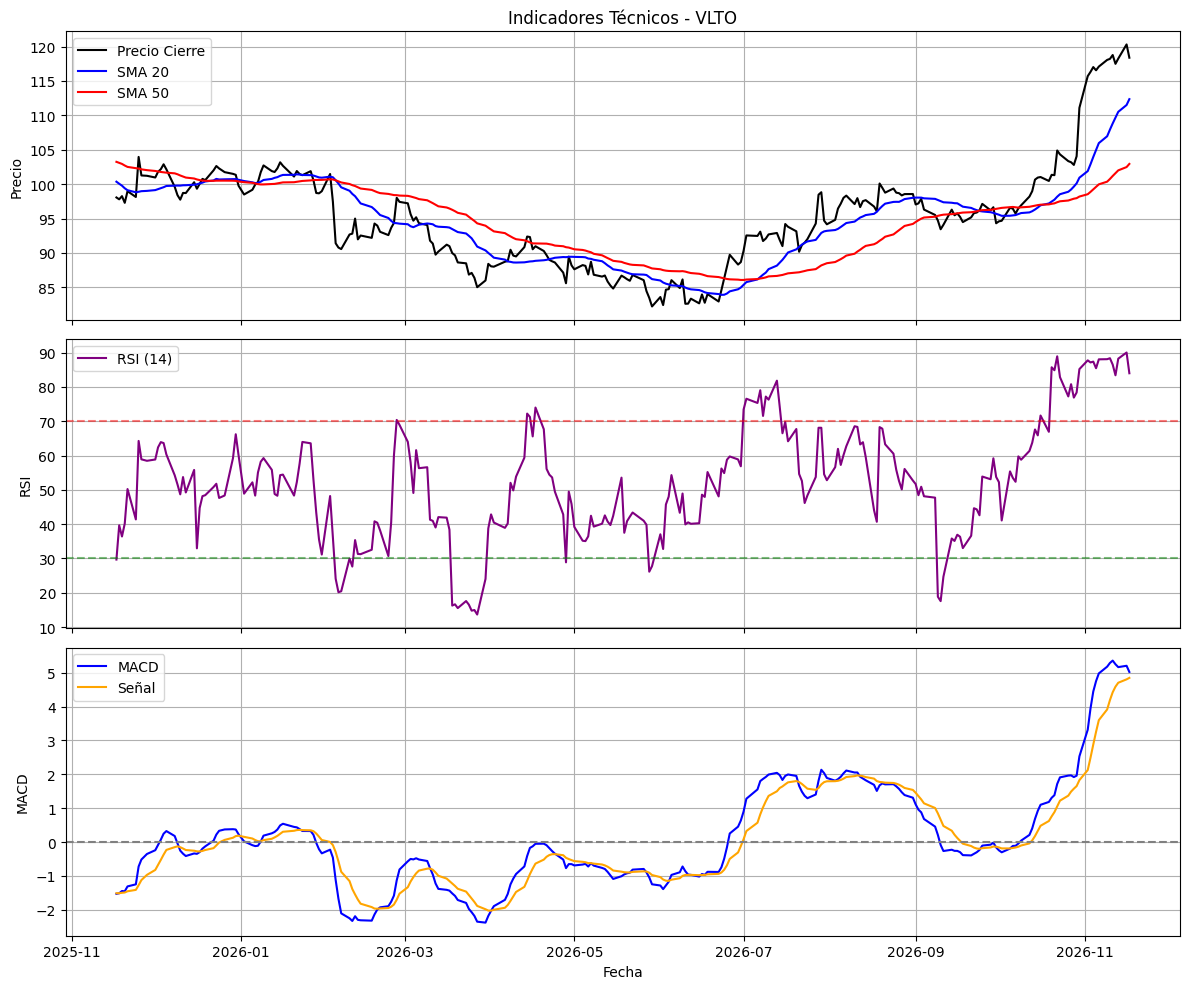


Generando gráficos para: CLX


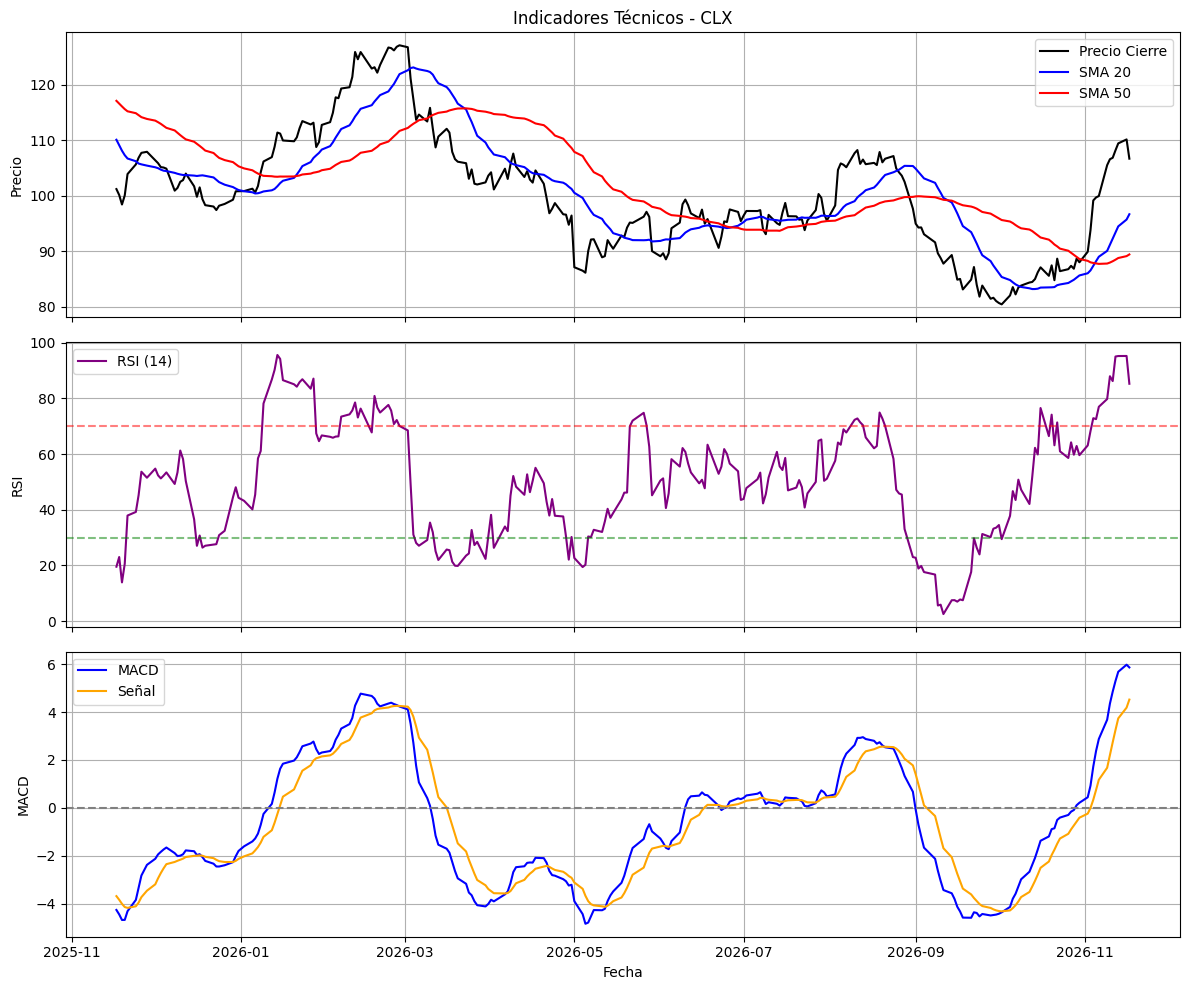


Generando gráficos para: WMT


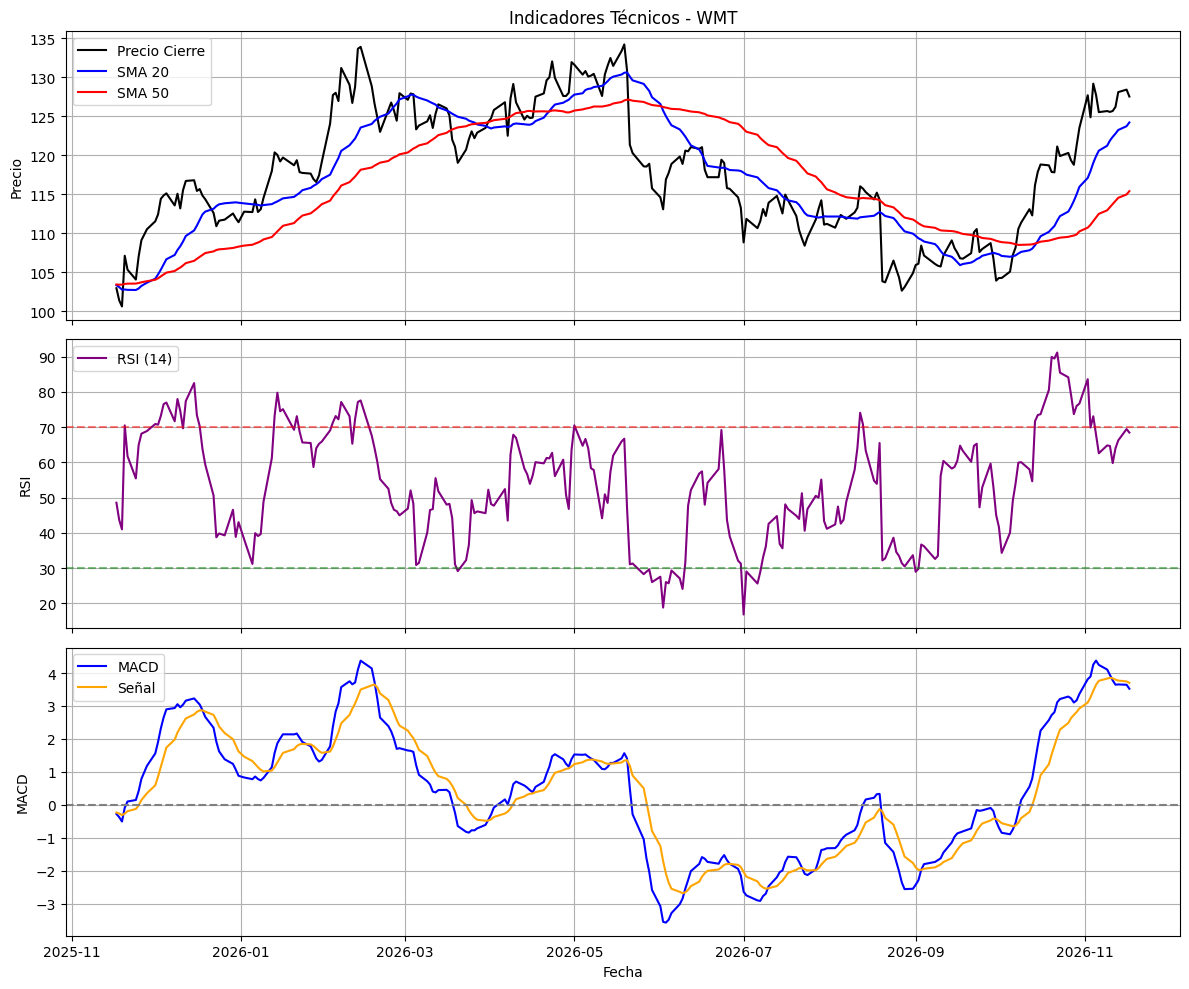

In [140]:
import matplotlib.pyplot as plt
import pandas as pd

print("=" * 70)
print("          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES")
print("=" * 70)

for ticker in top_tickers:
    print(f"\nGenerando gráficos para: {ticker.upper()}")

    # Preparar los datos
    df_tec = acciones_validas[ticker].copy()
    df_tec['Date'] = pd.to_datetime(df_tec['Date'])
    df_tec = df_tec.set_index('Date').sort_index()

    # 1. Medias Móviles Simples (SMA 20 y 50)
    df_tec['SMA_20'] = df_tec['Close'].rolling(window=20).mean()
    df_tec['SMA_50'] = df_tec['Close'].rolling(window=50).mean()

    # 2. RSI 14
    delta = df_tec['Close'].diff()
    ganancia = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    perdida = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = ganancia / perdida
    df_tec['RSI_14'] = 100 - (100 / (1 + rs))

    # 3. MACD
    ema_12 = df_tec['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tec['Close'].ewm(span=26, adjust=False).mean()
    df_tec['MACD'] = ema_12 - ema_26
    df_tec['MACD_Senal'] = df_tec['MACD'].ewm(span=9, adjust=False).mean()

    # Filtrar solo el último año bursátil para una mejor visualización (252 días)
    df_graf = df_tec.tail(252)

    # Crear la figura con 3 subgráficos
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    # Gráfico 1: Precio y Medias Móviles
    ax1.plot(df_graf.index, df_graf['Close'], label='Precio Cierre', color='black')
    ax1.plot(df_graf.index, df_graf['SMA_20'], label='SMA 20', color='blue')
    ax1.plot(df_graf.index, df_graf['SMA_50'], label='SMA 50', color='red')
    ax1.set_title(f'Indicadores Técnicos - {ticker.upper()}')
    ax1.set_ylabel('Precio')
    ax1.legend()
    ax1.grid(True)

    # Gráfico 2: RSI
    ax2.plot(df_graf.index, df_graf['RSI_14'], color='purple', label='RSI (14)')
    ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
    ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
    ax2.set_ylabel('RSI')
    ax2.legend(loc='upper left')
    ax2.grid(True)

    # Gráfico 3: MACD
    ax3.plot(df_graf.index, df_graf['MACD'], color='blue', label='MACD')
    ax3.plot(df_graf.index, df_graf['MACD_Senal'], color='orange', label='Señal')
    ax3.axhline(0, color='gray', linestyle='--')
    ax3.set_ylabel('MACD')
    ax3.set_xlabel('Fecha')
    ax3.legend(loc='upper left')
    ax3.grid(True)

    plt.tight_layout()
    plt.show()